# Rigid registration (ICP)

`register_rigid(source, target)` finds the rotation and translation that lay a scan onto its design, or one run's mesh onto another's, by iterative closest points, and returns the 4 × 4 matrix `transform` applies. Point-to-point pairs points with closest points; point-to-plane measures the distance to the target's tangent planes and converges in a handful of iterations. See `doc/registration.md`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def lumpy(subdivisions=4):
    s = mp.icosa_sphere(subdivisions=subdivisions)
    p = s.points / np.linalg.norm(s.points, axis=1)[:, None]
    p = p * [1.6, 1.0, 0.7] + 0.1 * np.sin(3 * p[:, [1, 2, 0]])
    return mp.Mesh(p, s.cells)


def rotation(axis, angle):
    a = np.asarray(axis, float) / np.linalg.norm(axis)
    K = np.array([[0, -a[2], a[1]], [a[2], 0, -a[0]], [-a[1], a[0], 0]])
    return np.eye(3) + np.sin(angle) * K + (1 - np.cos(angle)) * K @ K


def draw(ax, design, clouds, title):
    tris = design.cells_dict['triangle']
    ax.add_collection3d(Poly3DCollection(design.points[tris], facecolor='0.85', edgecolor='none', alpha=0.35))
    for pts, colour in clouds:
        ax.scatter(*pts.T, s=1.5, c=colour)
    ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.3, 1.3); ax.set_zlim(-1.0, 1.0)
    ax.set_box_aspect((3.6, 2.6, 2.0)); ax.set_axis_off(); ax.set_title(title)

## A scan onto its design

The design is a surface; the scan, 3 000 points sampled on it with noise, arrives rotated by 7° and shifted. Point-to-plane against the design's faces aligns it, and what remains is the scan noise.

[[ 0.99311  0.09842 -0.06358 -0.11084]
 [-0.09629  0.99471  0.03582  0.06976]
 [ 0.06677 -0.02945  0.99733 -0.04962]
 [ 0.       0.       0.       1.     ]]
{'initial_rms': 0.07856381871573175, 'rms': 0.0029542010048601358, 'iterations': 6, 'converged': True}
distance to the true scan positions: max 6.32e-04


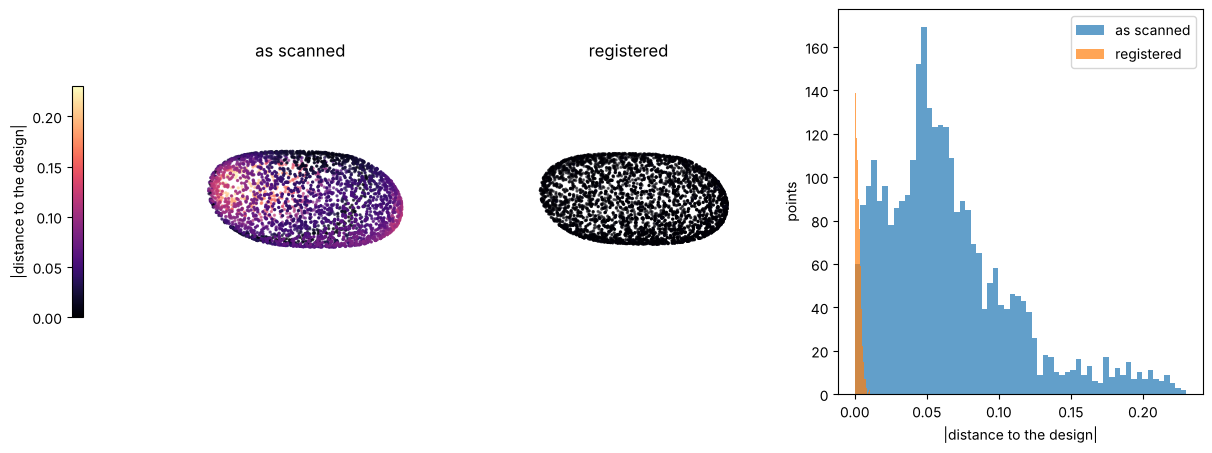

In [2]:
design = lumpy()
rng = np.random.default_rng(0)
tris = design.cells_dict['triangle'][rng.integers(0, len(design.cells_dict['triangle']), 3000)]
w = rng.dirichlet([1, 1, 1], 3000)
truth = np.einsum('ij,ijk->ik', w, design.points[tris]) + rng.normal(scale=0.003, size=(3000, 3))
R = rotation((1, 2, 3), np.radians(7))
scan = truth @ R.T + [0.12, -0.06, 0.04]

matrix, report = mp.register_rigid(scan, design, method='point_to_plane')
aligned = mp.transform(mp.Mesh(scan, []), matrix=matrix).points
print(np.array2string(matrix, precision=5, suppress_small=True))
print({k: report[k] for k in ('initial_rms', 'rms', 'iterations', 'converged')})
print(f'distance to the true scan positions: max {np.abs(aligned - truth).max():.2e}')

before = np.abs(mp.sample_distance(design, scan))
after = np.abs(mp.sample_distance(design, aligned))
fig = plt.figure(figsize=(16, 5))
for i, (pts, dist, title) in enumerate(((scan, before, 'as scanned'), (aligned, after, 'registered'))):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    sc = ax.scatter(*pts.T, s=2, c=dist, cmap='magma', vmin=0, vmax=before.max())
    ax.set_box_aspect((3.2, 2.0, 1.4)); ax.set_axis_off(); ax.set_title(title)
plt.colorbar(sc, ax=fig.axes, shrink=0.6, location='left', label='|distance to the design|')
ax = fig.add_subplot(1, 3, 3)
ax.hist(before, bins=60, alpha=0.7, label='as scanned'); ax.hist(after, bins=60, alpha=0.7, label='registered')
ax.set_xlabel('|distance to the design|'); ax.set_ylabel('points'); ax.legend()
plt.show()

## Point-to-plane against point-to-point

From the same start, point-to-point slides its closest points along the faces and converges only linearly; point-to-plane converges in a few iterations. The RMS per iteration shows it (each run capped at `max_iterations`).

Warning: register_rigid: no convergence in 1 iterations (rms 0.0617); raise max_iterations or start closer

Warning: register_rigid: no convergence in 2 iterations (rms 0.0505); raise max_iterations or start closer

Warning: register_rigid: no convergence in 3 iterations (rms 0.0422); raise max_iterations or start closer

Warning: register_rigid: no convergence in 4 iterations (rms 0.0358); raise max_iterations or start closer

Warning: register_rigid: no convergence in 5 iterations (rms 0.0306); raise max_iterations or start closer

Warning: register_rigid: no convergence in 6 iterations (rms 0.0265); raise max_iterations or start closer

... (70 outputs left out)

Warning: register_rigid: no convergence in 37 iterations (rms 0.00295); raise max_iterations or start closer

Warning: register_rigid: no convergence in 38 iterations (rms 0.00295); raise max_iterations or start closer

Warning: register_rigid: no convergence in 39 iterations (rms 0.00295); raise max_iterations or start closer

Warning: register_rigid: no convergence in 40 iterations (rms 0.00295); raise max_iterations or start closer

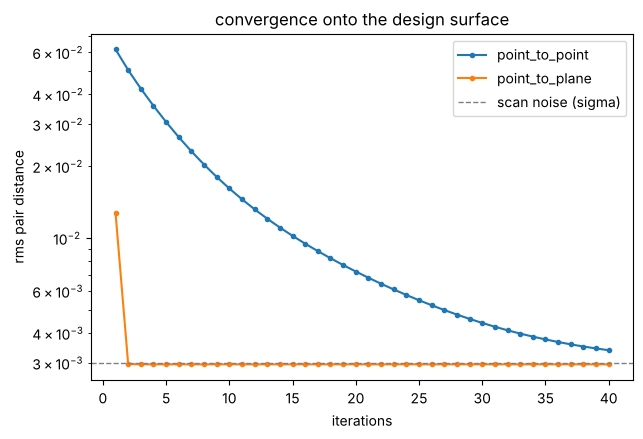

In [3]:
curves = {}
for method in ('point_to_point', 'point_to_plane'):
    rms = []
    for cap in range(1, 41):
        _, rep = mp.register_rigid(scan, design, method=method, max_iterations=cap, tolerance=0.0)
        rms.append(rep['rms'])
    curves[method] = rms
fig, ax = plt.subplots(figsize=(7, 4.5))
for method, rms in curves.items():
    ax.semilogy(range(1, 41), rms, 'o-', ms=3, label=method)
ax.axhline(0.003, color='0.5', ls='--', lw=1, label='scan noise (sigma)')
ax.set_xlabel('iterations'); ax.set_ylabel('rms pair distance'); ax.legend(); ax.set_title('convergence onto the design surface')
plt.show()

## Outliers and a coarse start

Points the target does not have (fixture clamps, the scan table) pull the alignment; `max_distance` drops pairs farther apart than a bound. ICP finds the nearest optimum only: a pose far off needs a coarse `initial` transform first.

In [4]:
clutter = rng.uniform([-2.5, -2.0, -1.4], [2.5, 2.0, -1.0], size=(400, 3))  # a table under the part
dirty = np.vstack([scan, clutter])
m_all, rep_all = mp.register_rigid(dirty, design, method='point_to_plane')
m_cut, rep_cut = mp.register_rigid(dirty, design, method='point_to_plane', max_distance=0.15)
for name, m, rep in (('every pair', m_all, rep_all), ('max_distance=0.15', m_cut, rep_cut)):
    err = np.abs(mp.transform(mp.Mesh(scan, []), matrix=m).points - truth).max()
    print(f'{name:>18}: {rep["num_pairs"]} pairs, rms {rep["rms"]:.4f}, scan error {err:.2e}')

far = truth @ rotation((0, 0, 1), np.radians(100)).T  # a quarter turn and more
_, lost = mp.register_rigid(far, design, method='point_to_plane')
coarse = np.eye(4); coarse[:3, :3] = rotation((0, 0, 1), np.radians(-90))
_, found = mp.register_rigid(far, design, method='point_to_plane', initial=coarse)
print(f'100 degrees off: rms {lost["rms"]:.3f} alone, {found["rms"]:.4f} from a coarse 90 degree start')

Warning: register_rigid: no convergence in 50 iterations (rms 0.384); raise max_iterations or start closer

        every pair: 3400 pairs, rms 0.3839, scan error 3.42e-01
 max_distance=0.15: 3000 pairs, rms 0.0030, scan error 6.32e-04


Warning: register_rigid: no convergence in 50 iterations (rms 0.0601); raise max_iterations or start closer

100 degrees off: rms 0.060 alone, 0.0030 from a coarse 90 degree start


## In a pipeline, and on the command line

`RegisterRigid` moves the mesh onto a `Target` file; the verb `register` prints the matrix (and with `--output` writes the moved source).

In [5]:
print('{"Op": "RegisterRigid", "Target": "design.stl", "Method": "point_to_plane", "MaxDistance": 0.15}')
print('meshioplusplus register scan.ply design.stl --method point_to_plane --output aligned.vtu --json')

{"Op": "RegisterRigid", "Target": "design.stl", "Method": "point_to_plane", "MaxDistance": 0.15}
meshioplusplus register scan.ply design.stl --method point_to_plane --output aligned.vtu --json
